# 🧠 ResNet-18 Image Classification Pipeline
## Garbage Classification (6 Classes) — CAK4WBB3 Computer Vision Tugas 1

This notebook implements a **complete, reproducible ResNet-18** fine-tuning pipeline for garbage classification using PyTorch.

### Pipeline Overview
1. **Environment Setup** — Install & import all dependencies, set global seeds.
2. **Dataset Ingestion** — Locate the Garbage Classification dataset (2,527 images, 6 classes).
3. **Stratified Train/Val/Test Split** (70/15/15) — Preserving class ratios.
4. **Data Preprocessing & Augmentation** — Augmentation ONLY on training set.
5. **Model Architecture** — Pretrained ResNet-18 (ImageNet), head replaced for 6-class output.
6. **Training Loop** — AdamW + ReduceLROnPlateau, 20 epochs, best-model checkpointing.
7. **Evaluation** — Classification metrics + computational efficiency metrics.
8. **Visualizations** — Training curves, confusion matrix, sample predictions.

### About ResNet-18
ResNet-18 is an 18-layer deep residual network that uses **identity skip connections** to address the
vanishing gradient problem in deep networks. The key insight is the residual mapping:

$$y = \mathcal{F}(x, \{W_i\}) + x$$

where $\mathcal{F}(x, \{W_i\})$ represents stacked $3 \times 3$ convolutional layers (a "basic block")
and $x$ is the identity shortcut. This allows gradients to flow directly through the skip connection,
enabling deeper networks to be trained effectively. ResNet-18 consists of 4 groups of basic blocks
(2 blocks each), with channel sizes [64, 128, 256, 512], plus an initial 7×7 conv layer and a final
fully connected layer.

## 1. Environment Setup

In [15]:
# Install dependencies (for Google Colab)
# Uncomment the following lines if running on Colab:
# !pip install torch torchvision scikit-learn seaborn matplotlib pandas numpy Pillow kagglehub --quiet

In [16]:
import os
import sys
import time
import random
import warnings
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

import torchvision
from torchvision import models, transforms
from torchvision.datasets import ImageFolder

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    accuracy_score,
)

from PIL import Image

warnings.filterwarnings("ignore")
print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.12.1
Torchvision version: 0.27.1
CUDA available: False


### 1.1 Reproducibility — Global Random Seeds

We set `SEED = 42` across all random number generators (`random`, `numpy`, `torch`, `torch.cuda`)
to ensure **reproducible results** across runs. Additionally, we set `torch.backends.cudnn.deterministic`
to `True` and `benchmark` to `False` to eliminate nondeterminism from cuDNN auto-tuner.

In [17]:
# ─── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42

def set_seed(seed: int = SEED):
    """Set random seeds for full reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)
print(f"✅ Global seed set to {SEED} for reproducibility.")

✅ Global seed set to 42 for reproducibility.


### 1.2 Hyperparameters & Configuration

All hyperparameters are **standardized** across models in this benchmark study to enable fair
comparisons between ResNet-18, MobileNetV2, and EfficientNet-B0.

In [18]:
# ─── Configuration ─────────────────────────────────────────────────────────────
CONFIG = {
    # Dataset
    "num_classes": 6,
    "image_size": 224,          # ResNet-18 expects 224×224 input
    "batch_size": 32,
    "num_workers": 0,           # DataLoader worker threads

    # Splits
    "train_ratio": 0.70,
    "val_ratio": 0.15,
    "test_ratio": 0.15,

    # Training
    "epochs": 20,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,

    # Normalization (ImageNet statistics)
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225],

    # Output
    "model_name": "resnet18",
    "output_dir": "outputs",
}

# Device selection
# Device selection: CUDA (NVIDIA) → MPS (Apple Silicon) → CPU
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print(f"📱 Device: {DEVICE}")

# Create output directory
os.makedirs(CONFIG["output_dir"], exist_ok=True)
print(f"📂 Outputs will be saved to: {CONFIG['output_dir']}/")

📱 Device: mps
📂 Outputs will be saved to: outputs/


## 2. Dataset Ingestion

The dataset is the **Garbage Classification** dataset from Kaggle containing 2,527 images across
6 classes: `cardboard` (403), `glass` (501), `metal` (410), `paper` (594), `plastic` (482), `trash` (137).

> **Note on class imbalance:** The `trash` class has only 137 images (5.4% of the dataset),
> while `paper` has 594 (23.5%). We use **stratified splitting** to ensure each split preserves
> the original class distribution. We also apply data augmentation during training to synthetically
> increase diversity and reduce overfitting on this relatively small (2,527 image) dataset.

The directory handling utility below searches for the nested `Garbage classification/Garbage classification/`
folder structure that this dataset typically has.

In [19]:
# ─── Dataset Path Resolution ───────────────────────────────────────────────────

def find_dataset_root(search_paths: list) -> str:
    """
    Locate the directory containing the 6 class subdirectories.

    The Kaggle Garbage Classification dataset often extracts to a nested
    structure: 'Garbage classification/Garbage classification/<classes>/'.
    This function searches common locations and resolves the correct root.

    Args:
        search_paths: List of directories to search for the dataset.

    Returns:
        Path to the directory containing class subdirectories.

    Raises:
        FileNotFoundError: If the dataset cannot be found.
    """
    expected_classes = {"cardboard", "glass", "metal", "paper", "plastic", "trash"}

    for base_path in search_paths:
        base = Path(base_path)
        if not base.exists():
            continue
        # Walk up to 3 levels deep to find the folder with 6 class subdirs
        for root, dirs, _ in os.walk(base):
            found_classes = set(dirs) & expected_classes
            if found_classes == expected_classes:
                print(f"✅ Dataset found at: {root}")
                return root
            # Don't recurse too deep
            if root.count(os.sep) - str(base).count(os.sep) >= 3:
                break

    raise FileNotFoundError(
        "Could not find the Garbage Classification dataset. "
        "Please download it from Kaggle and place it in one of these paths:\n"
        + "\n".join(f"  - {p}" for p in search_paths)
    )


# Search in common locations (adjust paths as needed)
SEARCH_PATHS = [
    ".",                                          # Current directory
    "..",                                         # Parent directory
    "../Garbage classification",                  # Sibling folder
    "Garbage classification",                     # Subdirectory
    os.path.expanduser("~/datasets"),             # Home datasets folder
    "/content/drive/MyDrive",                     # Google Drive on Colab
    "/content",                                   # Colab root
]

DATASET_ROOT = find_dataset_root(SEARCH_PATHS)
print(f"📁 Dataset root: {DATASET_ROOT}")

✅ Dataset found at: ../Garbage classification/Garbage classification
📁 Dataset root: ../Garbage classification/Garbage classification


In [20]:
# ─── Verify Dataset Structure ──────────────────────────────────────────────────

# Use ImageFolder to load the full dataset (for indexing & label extraction)
full_dataset = ImageFolder(root=DATASET_ROOT)

# Class names and distribution
class_names = full_dataset.classes
num_images = len(full_dataset)
targets = np.array(full_dataset.targets)

print(f"\n{'='*55}")
print(f"  GARBAGE CLASSIFICATION DATASET SUMMARY")
print(f"{'='*55}")
print(f"  Total images : {num_images}")
print(f"  Classes ({len(class_names)}): {class_names}")
print(f"{'='*55}")
print(f"\n  Per-class distribution:")

class_counts = {}
for idx, name in enumerate(class_names):
    count = int(np.sum(targets == idx))
    pct = count / num_images * 100
    class_counts[name] = count
    print(f"    {name:>12s}: {count:>4d} images ({pct:5.1f}%)")

print(f"\n  ✅ Satisfies ≥1,000 images and ≥5 classes requirements.")


  GARBAGE CLASSIFICATION DATASET SUMMARY
  Total images : 2527
  Classes (6): ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

  Per-class distribution:
       cardboard:  403 images ( 15.9%)
           glass:  501 images ( 19.8%)
           metal:  410 images ( 16.2%)
           paper:  594 images ( 23.5%)
         plastic:  482 images ( 19.1%)
           trash:  137 images (  5.4%)

  ✅ Satisfies ≥1,000 images and ≥5 classes requirements.


## 3. Stratified Train / Validation / Test Split

We split the dataset **70% / 15% / 15%** using `sklearn.model_selection.train_test_split` with
`stratify=targets`. This is critical because:

1. **Class imbalance:** The `trash` class has only 137 images. Without stratification, a random
   split could leave very few `trash` examples in the validation or test sets, making evaluation
   unreliable.
2. **Fair comparison:** Using the **exact same split** (controlled by `SEED=42`) for all models
   ensures we compare architectures on identical data.

### No Data Leakage Guarantee
- We split at the **image level** before any augmentation.
- **Training augmentation** (random crop, flip, rotation, color jitter) is ONLY applied to
  training images via a separate transform pipeline.
- Validation and test images receive ONLY deterministic `Resize(224)` + `Normalize()`.

In [21]:
# ─── Stratified Split ──────────────────────────────────────────────────────────

indices = np.arange(num_images)
labels = targets

# First split: 70% train, 30% temp (val+test)
train_idx, temp_idx, train_labels, temp_labels = train_test_split(
    indices, labels,
    test_size=(1 - CONFIG["train_ratio"]),
    stratify=labels,
    random_state=SEED,
)

# Second split: 50% of temp → 15% val, 15% test
val_idx, test_idx, val_labels, test_labels = train_test_split(
    temp_idx, temp_labels,
    test_size=0.5,
    stratify=temp_labels,
    random_state=SEED,
)

print(f"{'='*55}")
print(f"  STRATIFIED SPLIT SUMMARY")
print(f"{'='*55}")
print(f"  Training set   : {len(train_idx):>5d} images ({len(train_idx)/num_images*100:.1f}%)")
print(f"  Validation set : {len(val_idx):>5d} images ({len(val_idx)/num_images*100:.1f}%)")
print(f"  Test set       : {len(test_idx):>5d} images ({len(test_idx)/num_images*100:.1f}%)")
print(f"  Total          : {len(train_idx)+len(val_idx)+len(test_idx):>5d} images")
print(f"{'='*55}")

# Verify stratification — class distribution should be similar across splits
print(f"\n  Per-class distribution across splits:")
print(f"  {'Class':>12s} | {'Train':>6s} | {'Val':>5s} | {'Test':>5s}")
print(f"  {'-'*12}-+-{'-'*6}-+-{'-'*5}-+-{'-'*5}")
for idx, name in enumerate(class_names):
    tr = int(np.sum(train_labels == idx))
    va = int(np.sum(val_labels == idx))
    te = int(np.sum(test_labels == idx))
    print(f"  {name:>12s} | {tr:>6d} | {va:>5d} | {te:>5d}")

  STRATIFIED SPLIT SUMMARY
  Training set   :  1768 images (70.0%)
  Validation set :   379 images (15.0%)
  Test set       :   380 images (15.0%)
  Total          :  2527 images

  Per-class distribution across splits:
         Class |  Train |   Val |  Test
  -------------+--------+-------+------
     cardboard |    282 |    61 |    60
         glass |    350 |    75 |    76
         metal |    287 |    61 |    62
         paper |    416 |    89 |    89
       plastic |    337 |    72 |    73
         trash |     96 |    21 |    20


## 4. Data Preprocessing & Augmentation

### Why These Augmentations?
With only **2,527 images**, overfitting is a significant risk. We apply augmentations to the
**training set ONLY** to synthetically increase data diversity:

- **`RandomResizedCrop(224, scale=(0.8, 1.0))`** — Simulates slight zoom/crop variations,
  forcing the model to recognize objects at different scales.
- **`RandomHorizontalFlip(p=0.5)`** — Garbage items have no inherent horizontal orientation.
- **`RandomRotation(15°)`** — Items may appear at slight angles in real-world scenarios.
- **`ColorJitter(brightness=0.1, contrast=0.1)`** — Accounts for varying lighting conditions.

### Validation & Test Transforms
Only deterministic `Resize(224)` + `Normalize()` — **no augmentation**, ensuring consistent evaluation.

### ImageNet Normalization
We use ImageNet statistics `mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]` because
we're fine-tuning a model pretrained on ImageNet. This ensures the input distribution matches
what the pretrained weights expect.

In [22]:
# ─── Transform Pipelines ───────────────────────────────────────────────────────

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(CONFIG["image_size"], scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG["mean"], std=CONFIG["std"]),
])

val_test_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG["mean"], std=CONFIG["std"]),
])

print("✅ Transform pipelines defined.")
print(f"\n🔄 Training augmentation pipeline:")
for t in train_transform.transforms:
    print(f"   → {t}")
print(f"\n📐 Validation/Test pipeline (deterministic):")
for t in val_test_transform.transforms:
    print(f"   → {t}")

✅ Transform pipelines defined.

🔄 Training augmentation pipeline:
   → RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
   → RandomHorizontalFlip(p=0.5)
   → RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
   → ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
   → ToTensor()
   → Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

📐 Validation/Test pipeline (deterministic):
   → Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
   → ToTensor()
   → Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])


### 4.1 Custom Dataset Wrapper (Preventing Data Leakage)

**CRITICAL:** We create a `SubsetWithTransform` wrapper that applies a **specific transform
pipeline** to a subset of the full dataset. This ensures:
- Training images get augmentation transforms.
- Validation and test images get ONLY resize + normalize.

We cannot simply apply transforms to `ImageFolder` globally because that would leak augmentation
into validation/test evaluation.

In [23]:
# ─── Custom Dataset Wrapper ─────────────────────────────────────────────────────

class SubsetWithTransform(Dataset):
    """
    Wraps a Subset of an ImageFolder dataset with a specific transform.

    This prevents data leakage by ensuring augmentation is ONLY applied
    to the training split, while val/test get deterministic preprocessing.
    """

    def __init__(self, dataset: ImageFolder, indices: np.ndarray, transform=None):
        """
        Args:
            dataset: The full ImageFolder dataset.
            indices: Array of indices for this subset.
            transform: Transform pipeline to apply to images in this subset.
        """
        self.dataset = dataset
        self.indices = indices
        self.transform = transform
        self.targets = [dataset.targets[i] for i in indices]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        image_path, label = self.dataset.imgs[real_idx]

        # Load image (ensures we start from raw pixels every time)
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# Create subset datasets with appropriate transforms
train_dataset = SubsetWithTransform(full_dataset, train_idx, transform=train_transform)
val_dataset   = SubsetWithTransform(full_dataset, val_idx,   transform=val_test_transform)
test_dataset  = SubsetWithTransform(full_dataset, test_idx,  transform=val_test_transform)

print(f"✅ Dataset wrappers created:")
print(f"   Train : {len(train_dataset):>5d} images (WITH augmentation)")
print(f"   Val   : {len(val_dataset):>5d} images (deterministic only)")
print(f"   Test  : {len(test_dataset):>5d} images (deterministic only)")

✅ Dataset wrappers created:
   Train :  1768 images (WITH augmentation)
   Val   :   379 images (deterministic only)
   Test  :   380 images (deterministic only)


In [24]:
# ─── DataLoaders ───────────────────────────────────────────────────────────────

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,            # Shuffle training data each epoch
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,           # No shuffling for evaluation
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda"),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda"),
)

print(f"✅ DataLoaders created (batch_size={CONFIG['batch_size']}, num_workers={CONFIG['num_workers']}):")
print(f"   Train batches : {len(train_loader)}")
print(f"   Val batches   : {len(val_loader)}")
print(f"   Test batches  : {len(test_loader)}")

✅ DataLoaders created (batch_size=32, num_workers=0):
   Train batches : 56
   Val batches   : 12
   Test batches  : 12


## 5. Model Architecture — ResNet-18

### Architecture Details
ResNet-18 consists of:
- **Initial conv layer:** 7×7, 64 filters, stride 2 → BatchNorm → ReLU → 3×3 MaxPool
- **Layer 1:** 2 BasicBlocks, 64 channels (no downsampling)
- **Layer 2:** 2 BasicBlocks, 128 channels (stride 2 downsampling)
- **Layer 3:** 2 BasicBlocks, 256 channels (stride 2 downsampling)
- **Layer 4:** 2 BasicBlocks, 512 channels (stride 2 downsampling)
- **Global Average Pooling** → **FC layer** (512 → num_classes)

Each **BasicBlock** contains:
```
x → Conv3×3 → BN → ReLU → Conv3×3 → BN → (+x) → ReLU
```
The skip connection `+x` is the identity mapping $y = \mathcal{F}(x) + x$.

### Transfer Learning Strategy
We load **ImageNet-pretrained weights** and replace only the final FC layer for our 6-class task.
All layers are **unfrozen** for full fine-tuning, allowing the entire network to adapt to the
garbage classification domain. This works well because:
1. ImageNet features (edges, textures, shapes) transfer well to garbage images.
2. Our dataset is small (2,527 images), so starting from pretrained weights provides a strong
   initialization that reduces overfitting risk compared to training from scratch.

In [25]:
# ─── Model Initialization ──────────────────────────────────────────────────────

def build_resnet18(num_classes: int, pretrained: bool = True) -> nn.Module:
    """
    Build a ResNet-18 model with a custom classification head.

    Args:
        num_classes: Number of output classes.
        pretrained: Whether to load ImageNet-pretrained weights.

    Returns:
        Modified ResNet-18 model.
    """
    if pretrained:
        weights = models.ResNet18_Weights.IMAGENET1K_V1
        model = models.resnet18(weights=weights)
        print("✅ Loaded pretrained ResNet-18 (ImageNet1K_V1 weights).")
    else:
        model = models.resnet18(weights=None)
        print("⚠️  Initialized ResNet-18 from scratch (no pretrained weights).")

    # Replace the final fully connected layer
    # Original: nn.Linear(512, 1000) → New: nn.Linear(512, 6)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    print(f"   Replaced FC layer: {in_features} → {num_classes} classes")

    # Unfreeze ALL layers for full fine-tuning
    for param in model.parameters():
        param.requires_grad = True

    return model


model = build_resnet18(num_classes=CONFIG["num_classes"])
model = model.to(DEVICE)

# ─── Parameter Count ──────────────────────────────────────────────────────────
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n{'='*55}")
print(f"  RESNET-18 MODEL SUMMARY")
print(f"{'='*55}")
print(f"  Total parameters     : {total_params:>12,d}")
print(f"  Trainable parameters : {trainable_params:>12,d}")
print(f"  Non-trainable params : {total_params - trainable_params:>12,d}")
print(f"  Device               : {DEVICE}")
print(f"{'='*55}")

✅ Loaded pretrained ResNet-18 (ImageNet1K_V1 weights).
   Replaced FC layer: 512 → 6 classes

  RESNET-18 MODEL SUMMARY
  Total parameters     :   11,179,590
  Trainable parameters :   11,179,590
  Non-trainable params :            0
  Device               : mps


## 6. Training Loop

### Training Configuration
- **Loss:** `CrossEntropyLoss` — standard for multi-class classification.
- **Optimizer:** `AdamW` (lr=1e-4, weight_decay=1e-4) — AdamW decouples weight decay from the
  gradient update, providing better regularization than L2 penalty in Adam.
- **LR Scheduler:** `ReduceLROnPlateau` (factor=0.5, patience=3) — halves the learning rate
  when validation loss stops improving for 3 consecutive epochs.
- **Best Model Checkpointing:** We save the model state dict whenever validation accuracy improves,
  ensuring we evaluate on the best-performing checkpoint rather than the final epoch.

In [26]:
# ─── Loss, Optimizer, Scheduler ────────────────────────────────────────────────

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"],
)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=CONFIG["scheduler_factor"],
    patience=CONFIG["scheduler_patience"],
)

print(f"✅ Training components initialized:")
print(f"   Loss      : CrossEntropyLoss")
print(f"   Optimizer : AdamW (lr={CONFIG['learning_rate']}, weight_decay={CONFIG['weight_decay']})")
print(f"   Scheduler : ReduceLROnPlateau (factor={CONFIG['scheduler_factor']}, patience={CONFIG['scheduler_patience']})")
print(f"   Epochs    : {CONFIG['epochs']}")

✅ Training components initialized:
   Loss      : CrossEntropyLoss
   Optimizer : AdamW (lr=0.0001, weight_decay=0.0001)
   Scheduler : ReduceLROnPlateau (factor=0.5, patience=3)
   Epochs    : 20


In [27]:
# ─── Training & Validation Functions ───────────────────────────────────────────

def train_one_epoch(model, loader, criterion, optimizer, device):
    """
    Train the model for one epoch.

    Returns:
        Tuple of (average_loss, accuracy).
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


@torch.no_grad()
def validate(model, loader, criterion, device):
    """
    Evaluate the model on a validation/test set.

    Returns:
        Tuple of (average_loss, accuracy).
    """
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [28]:
# ─── Main Training Loop ────────────────────────────────────────────────────────

history = {
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": [],
    "lr": [], "epoch_time": [],
}

best_val_acc = 0.0
best_val_loss = float("inf")
best_model_state = None
best_epoch = 0

checkpoint_path = os.path.join(CONFIG["output_dir"], f"{CONFIG['model_name']}_best.pth")

print(f"\n{'='*70}")
print(f"  TRAINING RESNET-18 — {CONFIG['epochs']} Epochs")
print(f"{'='*70}")

# Measure total training time
total_train_start = time.perf_counter()

for epoch in range(1, CONFIG["epochs"] + 1):
    epoch_start = time.perf_counter()

    # Synchronize GPU timing if applicable
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    # Train
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)

    # Validate
    val_loss, val_acc = validate(model, val_loader, criterion, DEVICE)

    # Synchronize GPU timing
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - epoch_start

    # Record history
    current_lr = optimizer.param_groups[0]["lr"]
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["lr"].append(current_lr)
    history["epoch_time"].append(epoch_time)

    # Step scheduler (based on validation loss)
    scheduler.step(val_loss)

    # Best model checkpointing (based on validation accuracy)
    improved = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_val_loss = val_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, checkpoint_path)
        improved = " ★ BEST"

    # Print epoch summary
    print(
        f"  Epoch [{epoch:>2d}/{CONFIG['epochs']}] "
        f"| Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% "
        f"| Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% "
        f"| LR: {current_lr:.2e} | Time: {epoch_time:.1f}s{improved}"
    )

# Synchronize final timing
if torch.cuda.is_available():
    torch.cuda.synchronize()

total_train_time = time.perf_counter() - total_train_start
avg_epoch_time = total_train_time / CONFIG["epochs"]

print(f"\n{'='*70}")
print(f"  ✅ Training complete!")
print(f"  Best epoch           : {best_epoch}")
print(f"  Best validation acc  : {best_val_acc*100:.2f}%")
print(f"  Best validation loss : {best_val_loss:.4f}")
print(f"  Total training time  : {total_train_time:.2f}s")
print(f"  Avg time per epoch   : {avg_epoch_time:.2f}s")
print(f"  Checkpoint saved to  : {checkpoint_path}")
print(f"{'='*70}")


  TRAINING RESNET-18 — 20 Epochs
  Epoch [ 1/20] | Train Loss: 0.8016 | Train Acc: 71.83% | Val Loss: 0.4615 | Val Acc: 83.11% | LR: 1.00e-04 | Time: 45.5s ★ BEST
  Epoch [ 2/20] | Train Loss: 0.3070 | Train Acc: 90.38% | Val Loss: 0.4545 | Val Acc: 85.49% | LR: 1.00e-04 | Time: 35.6s ★ BEST
  Epoch [ 3/20] | Train Loss: 0.1978 | Train Acc: 94.74% | Val Loss: 0.4013 | Val Acc: 86.28% | LR: 1.00e-04 | Time: 36.1s ★ BEST
  Epoch [ 4/20] | Train Loss: 0.1593 | Train Acc: 95.53% | Val Loss: 0.3241 | Val Acc: 89.18% | LR: 1.00e-04 | Time: 34.5s ★ BEST
  Epoch [ 5/20] | Train Loss: 0.0816 | Train Acc: 97.96% | Val Loss: 0.2926 | Val Acc: 91.56% | LR: 1.00e-04 | Time: 35.0s ★ BEST
  Epoch [ 6/20] | Train Loss: 0.0709 | Train Acc: 98.19% | Val Loss: 0.2588 | Val Acc: 93.14% | LR: 1.00e-04 | Time: 33.8s ★ BEST
  Epoch [ 7/20] | Train Loss: 0.0743 | Train Acc: 97.91% | Val Loss: 0.3031 | Val Acc: 90.77% | LR: 1.00e-04 | Time: 34.0s
  Epoch [ 8/20] | Train Loss: 0.0483 | Train Acc: 99.15% | Val 

## 7. Evaluation on Test Set

We load the **best checkpoint** (highest validation accuracy) and evaluate on the **held-out test set**.
This ensures we report the performance of the best-generalizing model, not the potentially overfit
final-epoch model.

In [29]:
# ─── Load Best Model ───────────────────────────────────────────────────────────

model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
model.eval()
print(f"✅ Loaded best model from epoch {best_epoch} (val_acc={best_val_acc*100:.2f}%)")

✅ Loaded best model from epoch 15 (val_acc=93.93%)


### 7.1 Classification Performance Metrics

We compute:
- **Overall test accuracy**
- **Macro-averaged** precision, recall, F1 (treats all classes equally)
- **Weighted-averaged** precision, recall, F1 (weighted by class support)
- **Per-class classification report** with all 6 garbage classes

In [30]:
# ─── Collect Predictions ───────────────────────────────────────────────────────

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

# ─── Overall Accuracy ─────────────────────────────────────────────────────────
test_accuracy = accuracy_score(all_labels, all_preds)

# ─── Precision, Recall, F1 ────────────────────────────────────────────────────
macro_prec, macro_rec, macro_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="macro", zero_division=0
)
weighted_prec, weighted_rec, weighted_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="weighted", zero_division=0
)

# ─── Full Classification Report ───────────────────────────────────────────────
report = classification_report(all_labels, all_preds, target_names=class_names, digits=4)

print(f"\n{'='*60}")
print(f"  RESNET-18 — TEST SET CLASSIFICATION RESULTS")
print(f"{'='*60}")
print(f"  Overall Test Accuracy : {test_accuracy*100:.2f}%")
print(f"{'='*60}")
print(f"  Macro-Averaged    Precision: {macro_prec:.4f} | Recall: {macro_rec:.4f} | F1: {macro_f1:.4f}")
print(f"  Weighted-Averaged Precision: {weighted_prec:.4f} | Recall: {weighted_rec:.4f} | F1: {weighted_f1:.4f}")
print(f"{'='*60}")
print(f"\n  Full Per-Class Classification Report:")
print(report)


  RESNET-18 — TEST SET CLASSIFICATION RESULTS
  Overall Test Accuracy : 92.11%
  Macro-Averaged    Precision: 0.9368 | Recall: 0.9134 | F1: 0.9217
  Weighted-Averaged Precision: 0.9275 | Recall: 0.9211 | F1: 0.9214

  Full Per-Class Classification Report:
              precision    recall  f1-score   support

   cardboard     1.0000    0.9167    0.9565        60
       glass     0.9706    0.8684    0.9167        76
       metal     0.8267    1.0000    0.9051        62
       paper     0.8947    0.9551    0.9239        89
     plastic     0.9286    0.8904    0.9091        73
       trash     1.0000    0.8500    0.9189        20

    accuracy                         0.9211       380
   macro avg     0.9368    0.9134    0.9217       380
weighted avg     0.9275    0.9211    0.9214       380



### 7.2 Computational Complexity & Efficiency Metrics

We measure:
- **Total & trainable parameters**
- **Model disk size (MB)** — size of the saved `.pth` checkpoint
- **Total training time & average time per epoch**
- **Inference latency (ms/image)** and **throughput (images/sec)** — measured over the full test set

In [31]:
# ─── Model Size on Disk ────────────────────────────────────────────────────────
model_size_mb = os.path.getsize(checkpoint_path) / (1024 * 1024)

# ─── Inference Latency & Throughput ────────────────────────────────────────────
# Warm-up run (for GPU JIT compilation / caching)
with torch.no_grad():
    dummy = torch.randn(1, 3, 224, 224).to(DEVICE)
    _ = model(dummy)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

# Measure inference time over entire test set
num_test_images = len(test_dataset)

if torch.cuda.is_available():
    torch.cuda.synchronize()

inference_start = time.perf_counter()
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)
        _ = model(images)

if torch.cuda.is_available():
    torch.cuda.synchronize()

inference_time = time.perf_counter() - inference_start
latency_ms = (inference_time * 1000) / num_test_images
throughput = num_test_images / inference_time

# ─── Summary Dictionary ───────────────────────────────────────────────────────
metrics_summary = {
    "Model": "ResNet-18",
    "Total Parameters": f"{total_params:,}",
    "Trainable Parameters": f"{trainable_params:,}",
    "Model Size (MB)": f"{model_size_mb:.2f}",
    "Total Training Time (s)": f"{total_train_time:.2f}",
    "Avg Time per Epoch (s)": f"{avg_epoch_time:.2f}",
    "Test Accuracy (%)": f"{test_accuracy*100:.2f}",
    "Macro Precision": f"{macro_prec:.4f}",
    "Macro Recall": f"{macro_rec:.4f}",
    "Macro F1-Score": f"{macro_f1:.4f}",
    "Weighted Precision": f"{weighted_prec:.4f}",
    "Weighted Recall": f"{weighted_rec:.4f}",
    "Weighted F1-Score": f"{weighted_f1:.4f}",
    "Inference Latency (ms/img)": f"{latency_ms:.2f}",
    "Throughput (img/s)": f"{throughput:.2f}",
    "Best Epoch": str(best_epoch),
}

print(f"\n{'='*60}")
print(f"  RESNET-18 — COMPUTATIONAL EFFICIENCY METRICS")
print(f"{'='*60}")
for key, value in metrics_summary.items():
    print(f"  {key:<30s}: {value}")
print(f"{'='*60}")

# ─── Save Metrics to CSV ──────────────────────────────────────────────────────
metrics_df = pd.DataFrame([metrics_summary])
metrics_csv_path = os.path.join(CONFIG["output_dir"], f"{CONFIG['model_name']}_metrics.csv")
metrics_df.to_csv(metrics_csv_path, index=False)
print(f"\n📄 Metrics saved to: {metrics_csv_path}")


  RESNET-18 — COMPUTATIONAL EFFICIENCY METRICS
  Model                         : ResNet-18
  Total Parameters              : 11,179,590
  Trainable Parameters          : 11,179,590
  Model Size (MB)               : 42.72
  Total Training Time (s)       : 718.35
  Avg Time per Epoch (s)        : 35.92
  Test Accuracy (%)             : 92.11
  Macro Precision               : 0.9368
  Macro Recall                  : 0.9134
  Macro F1-Score                : 0.9217
  Weighted Precision            : 0.9275
  Weighted Recall               : 0.9211
  Weighted F1-Score             : 0.9214
  Inference Latency (ms/img)    : 4.64
  Throughput (img/s)            : 215.65
  Best Epoch                    : 15

📄 Metrics saved to: outputs/resnet18_metrics.csv


## 8. Visualizations

### 8.1 Training & Validation Curves
Side-by-side loss and accuracy curves across epochs. This helps identify:
- **Overfitting:** when validation loss diverges from training loss.
- **Underfitting:** when both losses remain high.
- **Learning rate effects:** visible as sudden drops when the scheduler reduces LR.

📊 Saved: outputs/resnet18_training_curves.png


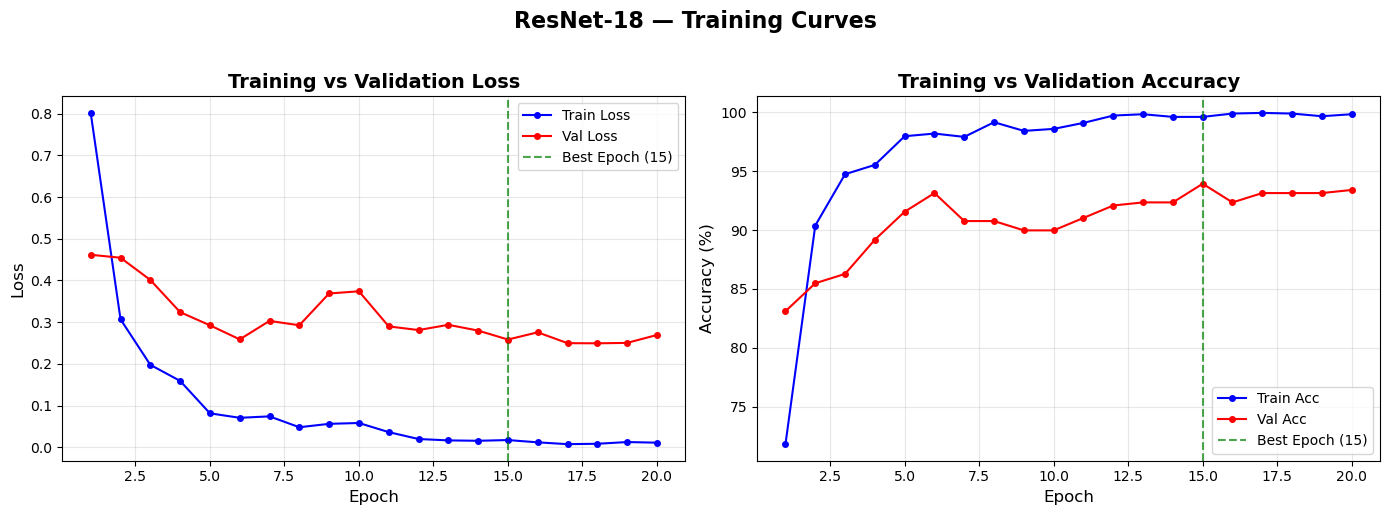

In [32]:
# ─── Plot 1: Training Curves ───────────────────────────────────────────────────

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, CONFIG["epochs"] + 1)

# Loss curves
ax1.plot(epochs_range, history["train_loss"], "b-o", markersize=4, label="Train Loss")
ax1.plot(epochs_range, history["val_loss"], "r-o", markersize=4, label="Val Loss")
ax1.axvline(x=best_epoch, color="green", linestyle="--", alpha=0.7, label=f"Best Epoch ({best_epoch})")
ax1.set_xlabel("Epoch", fontsize=12)
ax1.set_ylabel("Loss", fontsize=12)
ax1.set_title("Training vs Validation Loss", fontsize=14, fontweight="bold")
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Accuracy curves
ax2.plot(epochs_range, [a * 100 for a in history["train_acc"]], "b-o", markersize=4, label="Train Acc")
ax2.plot(epochs_range, [a * 100 for a in history["val_acc"]], "r-o", markersize=4, label="Val Acc")
ax2.axvline(x=best_epoch, color="green", linestyle="--", alpha=0.7, label=f"Best Epoch ({best_epoch})")
ax2.set_xlabel("Epoch", fontsize=12)
ax2.set_ylabel("Accuracy (%)", fontsize=12)
ax2.set_title("Training vs Validation Accuracy", fontsize=14, fontweight="bold")
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

fig.suptitle("ResNet-18 — Training Curves", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()

curves_path = os.path.join(CONFIG["output_dir"], "resnet18_training_curves.png")
fig.savefig(curves_path, dpi=300, bbox_inches="tight")
print(f"📊 Saved: {curves_path}")
plt.show()

### 8.2 Confusion Matrix
A 6×6 heatmap showing prediction distribution across classes. The diagonal represents correct
predictions; off-diagonal cells reveal systematic misclassification patterns (e.g., `metal` confused
with `trash`, or `glass` confused with `plastic`).

📊 Saved: outputs/resnet18_confusion_matrix.png


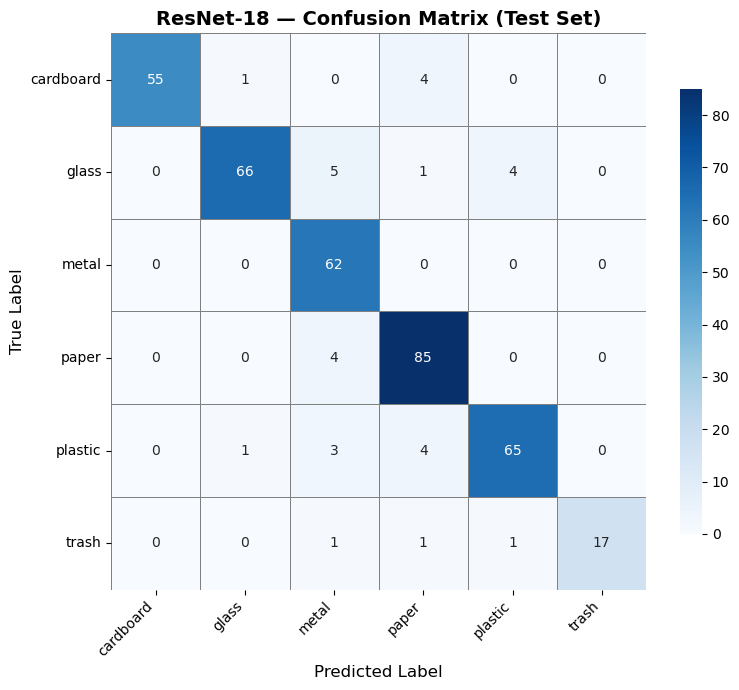

In [33]:
# ─── Plot 2: Confusion Matrix ──────────────────────────────────────────────────

cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"shrink": 0.8},
    ax=ax,
    linewidths=0.5,
    linecolor="gray",
)
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
ax.set_title("ResNet-18 — Confusion Matrix (Test Set)", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = os.path.join(CONFIG["output_dir"], "resnet18_confusion_matrix.png")
fig.savefig(cm_path, dpi=300, bbox_inches="tight")
print(f"📊 Saved: {cm_path}")
plt.show()

### 8.3 Sample Predictions
A 3×4 grid of 12 test images showing the original image, true label, predicted label, and
confidence score. Titles are **green** for correct predictions and **red** for misclassifications.

📊 Saved: outputs/resnet18_sample_predictions.png


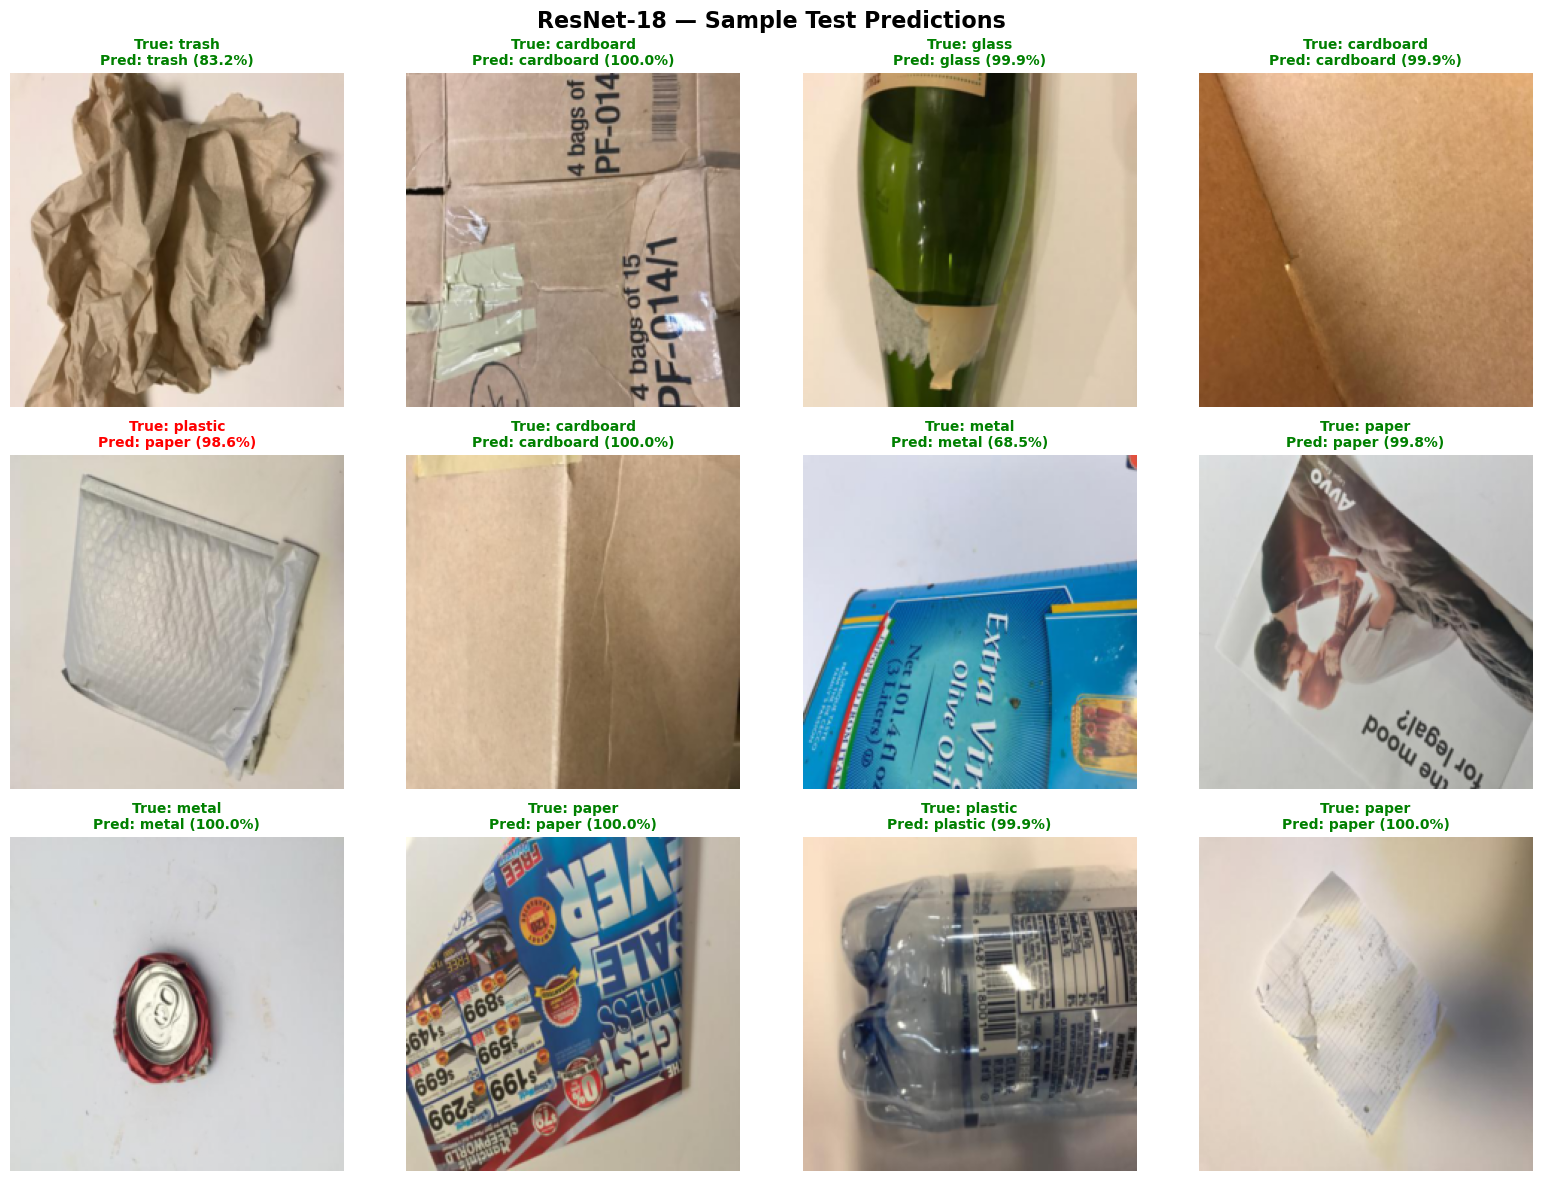

In [34]:
# ─── Plot 3: Sample Predictions ────────────────────────────────────────────────

def denormalize(tensor, mean, std):
    """Reverse ImageNet normalization for visualization."""
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return torch.clamp(tensor * std + mean, 0, 1)


# Select 12 random test images (mix of correct and incorrect if possible)
np.random.seed(SEED)
sample_indices = np.random.choice(len(test_dataset), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, idx in enumerate(sample_indices):
    image, true_label = test_dataset[idx]

    # Get prediction
    with torch.no_grad():
        output = model(image.unsqueeze(0).to(DEVICE))
        prob = torch.softmax(output, dim=1)
        confidence, pred_label = prob.max(1)
        confidence = confidence.item() * 100
        pred_label = pred_label.item()

    # Denormalize for display
    img_display = denormalize(image, CONFIG["mean"], CONFIG["std"])
    img_np = img_display.permute(1, 2, 0).numpy()

    # Plot
    axes[i].imshow(img_np)
    axes[i].axis("off")

    true_name = class_names[true_label]
    pred_name = class_names[pred_label]
    is_correct = true_label == pred_label
    color = "green" if is_correct else "red"

    axes[i].set_title(
        f"True: {true_name}\nPred: {pred_name} ({confidence:.1f}%)",
        fontsize=10,
        color=color,
        fontweight="bold",
    )

fig.suptitle("ResNet-18 — Sample Test Predictions", fontsize=16, fontweight="bold")
plt.tight_layout()

samples_path = os.path.join(CONFIG["output_dir"], "resnet18_sample_predictions.png")
fig.savefig(samples_path, dpi=300, bbox_inches="tight")
print(f"📊 Saved: {samples_path}")
plt.show()

## 9. Summary — Ready for Report

The following formatted table can be directly pasted into the 3-page PDF report for the
multi-architecture comparison (ResNet-18 vs. MobileNetV2 vs. EfficientNet-B0).

In [35]:
# ─── Final Summary Table ───────────────────────────────────────────────────────

print(f"\n{'='*70}")
print(f"  RESNET-18 — COMPLETE RESULTS SUMMARY")
print(f"  (Ready for 3-Page Report)")
print(f"{'='*70}")
print(f"")
print(f"  ┌──────────────────────────────────────────────────────────────┐")
print(f"  │                 CLASSIFICATION METRICS                       │")
print(f"  ├──────────────────────────────┬───────────────────────────────┤")
print(f"  │ Overall Test Accuracy        │ {test_accuracy*100:>27.2f}% │")
print(f"  │ Macro Precision              │ {macro_prec:>28.4f} │")
print(f"  │ Macro Recall                 │ {macro_rec:>28.4f} │")
print(f"  │ Macro F1-Score               │ {macro_f1:>28.4f} │")
print(f"  │ Weighted Precision           │ {weighted_prec:>28.4f} │")
print(f"  │ Weighted Recall              │ {weighted_rec:>28.4f} │")
print(f"  │ Weighted F1-Score            │ {weighted_f1:>28.4f} │")
print(f"  ├──────────────────────────────┼───────────────────────────────┤")
print(f"  │              EFFICIENCY METRICS                              │")
print(f"  ├──────────────────────────────┼───────────────────────────────┤")
print(f"  │ Total Parameters             │ {total_params:>28,} │")
print(f"  │ Trainable Parameters         │ {trainable_params:>28,} │")
print(f"  │ Model Size (MB)              │ {model_size_mb:>27.2f}  │")
print(f"  │ Total Training Time (s)      │ {total_train_time:>27.2f}  │")
print(f"  │ Avg Time per Epoch (s)       │ {avg_epoch_time:>27.2f}  │")
print(f"  │ Inference Latency (ms/img)   │ {latency_ms:>27.2f}  │")
print(f"  │ Throughput (img/s)           │ {throughput:>27.2f}  │")
print(f"  │ Best Epoch                   │ {best_epoch:>28d} │")
print(f"  └──────────────────────────────┴───────────────────────────────┘")
print(f"")
print(f"  📊 Visualizations saved:")
print(f"     • {curves_path}")
print(f"     • {cm_path}")
print(f"     • {samples_path}")
print(f"  📄 Metrics CSV: {metrics_csv_path}")
print(f"  💾 Best model : {checkpoint_path}")
print(f"{'='*70}")


  RESNET-18 — COMPLETE RESULTS SUMMARY
  (Ready for 3-Page Report)

  ┌──────────────────────────────────────────────────────────────┐
  │                 CLASSIFICATION METRICS                       │
  ├──────────────────────────────┬───────────────────────────────┤
  │ Overall Test Accuracy        │                       92.11% │
  │ Macro Precision              │                       0.9368 │
  │ Macro Recall                 │                       0.9134 │
  │ Macro F1-Score               │                       0.9217 │
  │ Weighted Precision           │                       0.9275 │
  │ Weighted Recall              │                       0.9211 │
  │ Weighted F1-Score            │                       0.9214 │
  ├──────────────────────────────┼───────────────────────────────┤
  │              EFFICIENCY METRICS                              │
  ├──────────────────────────────┼───────────────────────────────┤
  │ Total Parameters             │                   11,179,590 │
 

In [36]:
# ─── Save Training History ─────────────────────────────────────────────────────

history_df = pd.DataFrame({
    "epoch": list(range(1, CONFIG["epochs"] + 1)),
    "train_loss": history["train_loss"],
    "train_acc": history["train_acc"],
    "val_loss": history["val_loss"],
    "val_acc": history["val_acc"],
    "learning_rate": history["lr"],
    "epoch_time_s": history["epoch_time"],
})

history_csv_path = os.path.join(CONFIG["output_dir"], f"{CONFIG['model_name']}_training_history.csv")
history_df.to_csv(history_csv_path, index=False)
print(f"📄 Training history saved to: {history_csv_path}")
print(history_df.to_string(index=False))

📄 Training history saved to: outputs/resnet18_training_history.csv
 epoch  train_loss  train_acc  val_loss  val_acc  learning_rate  epoch_time_s
     1    0.801621   0.718326  0.461525 0.831135       0.000100     45.454012
     2    0.307017   0.903846  0.454512 0.854881       0.000100     35.593160
     3    0.197817   0.947398  0.401277 0.862797       0.000100     36.142144
     4    0.159330   0.955317  0.324099 0.891821       0.000100     34.509870
     5    0.081623   0.979638  0.292564 0.915567       0.000100     34.976322
     6    0.070892   0.981900  0.258845 0.931398       0.000100     33.826840
     7    0.074311   0.979072  0.303098 0.907652       0.000100     33.979691
     8    0.048277   0.991516  0.292630 0.907652       0.000100     34.086414
     9    0.056403   0.984163  0.368815 0.899736       0.000100     34.509187
    10    0.058465   0.985860  0.374071 0.899736       0.000100     35.454551
    11    0.036549   0.990950  0.289912 0.910290       0.000050     36.8757